# 02 - Space weather table and storm catalog (Apr 2024 - Apr 2025)

Goal: one clean hourly space-weather table for the whole study period and a list of storms.

- **Table** (`data/processed/spaceweather.parquet`): one row per hour with ap, Dst, Kp (stored as given,
  never averaged), daily F10.7 and its 81-day centred mean. Source: NASA OMNI2 (2024 and 2025 files).
- **Storm catalog** (`data/processed/storms.parquet`): a storm is Dst below -50 nT; dips less than
  3 days apart are one event. Classes by lowest Dst: moderate (-50 to -100), strong (-100 to -200),
  severe (-200 to -350), extreme (below -350).

All logic lives in `src/omni_io.py` and `src/storms.py`; this notebook only calls it.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.omni_io import build_spaceweather, load_spaceweather
from src.storms import storm_catalog
from src.plots import plot_dst_with_storms, plot_f107

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
pd.set_option("display.width", 200)

## 1. Hourly space-weather table

`build_spaceweather` downloads the OMNI2 files if needed, turns fill values into NaN, puts everything
on a complete hourly grid and prints any missing hours.

**F10.7 flare spikes.** The daily F10.7 is one measurement around local noon. If a solar flare is going on
at that moment the value jumps for that single day. On 30 Jul 2024 OMNI2 has 412.9 sfu between days of
about 230 and 242 sfu. That is not the UV background that heats the thermosphere, so such one-day spikes
(more than 1.5x the 7-day median) are replaced by the mean of the neighbouring days and marked in `f107_flare`.

In [2]:
sw = build_spaceweather().set_index("time")
print(sw.shape)
sw.describe().round(1)

F10.7 flare spike on 2024-07-30: 412.9 -> 236.1 sfu
No missing hours (9480 hours, 2024-04-01 00:00:00 to 2025-04-30 23:00:00).
(9480, 6)


,ap,dst,kp,f107,f107_81d
count,9480.0,9480.0,9480.0,9480.0,9480.0
mean,13.8,-15.4,2.2,192.6,192.1
std,24.7,30.6,1.4,37.7,20.5
min,0.0,-406.0,0.0,111.7,150.3
25%,5.0,-24.0,1.3,165.1,176.5
50%,7.0,-10.5,2.0,182.0,189.8
75%,15.0,2.0,3.0,217.8,207.4
max,400.0,71.0,9.0,345.4,228.6


## 2. Storm catalog

In [3]:
storms = storm_catalog(sw["dst"], out_path="default")
storms

,storm_id,onset_time,main_onset,peak_time,min_dst,class,recovery_end,hours_below_50
0,1,2024-04-15 13:00:00,2024-04-19 00:00:00,2024-04-19 19:00:00,-117.0,strong,2024-04-22 08:00:00,40
1,2,2024-04-25 19:00:00,2024-04-25 19:00:00,2024-04-26 16:00:00,-51.0,moderate,2024-04-27 01:00:00,1
2,3,2024-05-02 09:00:00,2024-05-02 09:00:00,2024-05-02 19:00:00,-89.0,moderate,2024-05-03 13:00:00,11
3,4,2024-05-10 17:00:00,2024-05-10 17:00:00,2024-05-11 02:00:00,-406.0,extreme,2024-05-19 10:00:00,121
4,5,2024-06-27 17:00:00,2024-06-27 17:00:00,2024-06-28 12:00:00,-107.0,strong,2024-06-29 20:00:00,30
5,6,2024-08-03 19:00:00,2024-08-03 19:00:00,2024-08-04 17:00:00,-100.0,moderate,2024-08-05 07:00:00,19
6,7,2024-08-11 19:00:00,2024-08-11 19:00:00,2024-08-12 16:00:00,-188.0,strong,2024-08-14 13:00:00,42
7,8,2024-08-27 09:00:00,2024-08-27 09:00:00,2024-08-28 06:00:00,-76.0,moderate,2024-09-01 07:00:00,16
8,9,2024-09-12 04:00:00,2024-09-12 04:00:00,2024-09-12 14:00:00,-121.0,strong,2024-09-20 02:00:00,100
9,10,2024-09-24 05:00:00,2024-09-24 05:00:00,2024-09-25 05:00:00,-53.0,moderate,2024-09-26 01:00:00,2


`onset_time` is the start of the Dst drop before Dst first crosses -50 nT. When an earlier, weaker dip
was merged into the same event, the drop that leads to the peak starts later: that is `main_onset`.
For the October 2024 storm the merged event starts with a moderate dip on Oct 7-8 (`onset_time` Oct 6),
while the G4 main phase starts on Oct 10 (`main_onset`). Use `main_onset` when the question is about
the big drop itself.

In [4]:
counts = storms["class"].value_counts().reindex(["moderate", "strong", "severe", "extreme"], fill_value=0)
print(counts.to_string())
print("total:", len(storms))

class
moderate    11
strong       6
severe       2
extreme      1
total: 20


## 3. Plots

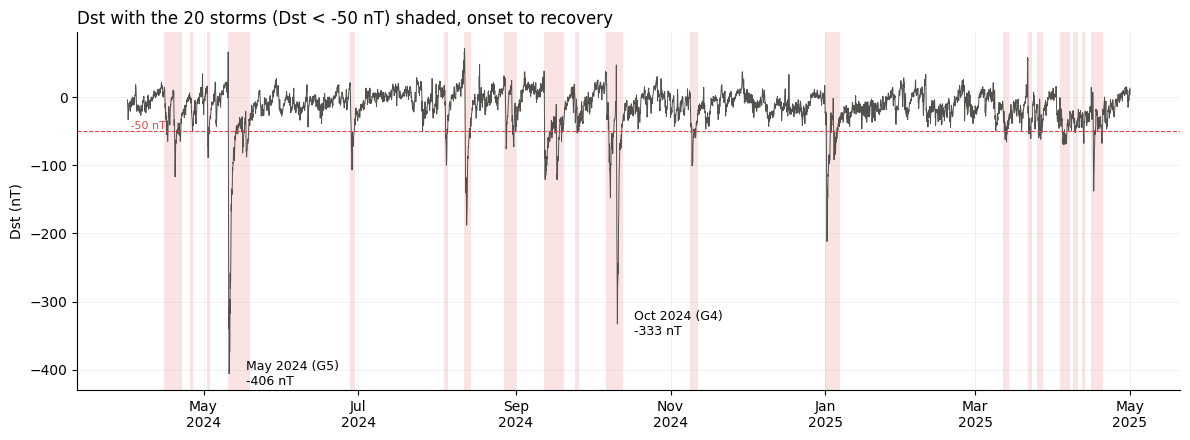

In [5]:
may_id = storms.loc[storms["min_dst"].idxmin(), "storm_id"]
oct_id = storms.loc[(storms["peak_time"] >= "2024-10-10") & (storms["peak_time"] < "2024-10-12"), "storm_id"].iloc[0]
fig = plot_dst_with_storms(sw, storms, labels={may_id: "May 2024 (G5)", oct_id: "Oct 2024 (G4)"},
                           out_path=RESULTS / "spaceweather_dst_storms.png")

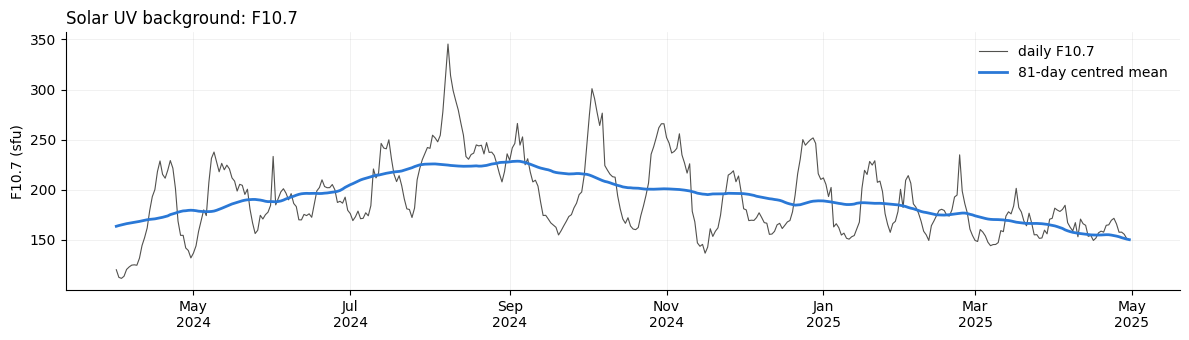

In [6]:
fig = plot_f107(sw, out_path=RESULTS / "spaceweather_f107.png")

## 4. Summary

**20 storms** with Dst below -50 nT between 1 Apr 2024 and 30 Apr 2025:

| class | Dst range | storms |
|---|---|---|
| moderate | -50 to -100 nT | 11 |
| strong | -100 to -200 nT | 6 |
| severe | -200 to -350 nT | 2 (Oct 2024, -333 nT; 1 Jan 2025, -212 nT) |
| extreme | below -350 nT | 1 (May 2024, -406 nT) |

**Is that enough for clustered standard errors?** Yes, just about: 20 clusters is above the ~15 we aimed for.
It is still a small number of clusters, so we should use a small-sample correction (e.g. wild cluster
bootstrap or CR2 / t(G-1) critical values) rather than plain cluster-robust standard errors. Only 3 storms
are severe or extreme, so any result about the strongest storms rests on very few events.

**Things to note:**
- No missing hours in OMNI2 for the period. One F10.7 flare spike (30 Jul 2024) was replaced.
- The Aug 4 2024 storm has min Dst exactly -100 nT and counts as moderate (boundaries go to the weaker class).
- Because of the 3-day merge, the April 2024 and October 2024 events each contain an earlier weaker dip;
  their `onset_time` is days before the peak. `main_onset` marks the main drop.
- Several storms in Mar-Apr 2025 are only 3-4 days apart. Their windows do not overlap, but the after-storm
  window of one is the before-storm window of the next; keep this in mind when choosing event windows.
- F10.7 ranges from ~110 to ~345 sfu (81-day mean ~150 to ~230), peaking in Aug 2024 near solar maximum.
  It changes a lot within the year, which is why it must be a confounder.